# Surfaces

In [1]:
#| include: false
import warnings, osmnx

warnings.filterwarnings("ignore")
osmnx.settings.overpass_settings = '[out:json][timeout:90][date:"2021-10-07T00:00:00Z"]'

In [2]:
import pandas
import osmnx
import geopandas as gpd
import rioxarray
import xarray
import datashader
import contextily as cx
from shapely import geometry
import matplotlib.pyplot as plt

In [3]:
pop = rioxarray.open_rasterio("../data/ghsl/ghsl_sao_paulo.tif")

In [4]:
# what is the datatype

type(pop)

xarray.core.dataarray.DataArray

In [5]:
pop

<xarray.DataArray (band: 1, y: 416, x: 468)> Size: 779kB
[194688 values with dtype=float32]
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 3kB -2.822e+06 -2.822e+06 ... -2.926e+06 -2.926e+06
  * x            (x) float64 4kB -4.482e+06 -4.482e+06 ... -4.365e+06 -4.365e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    _FillValue:     -200.0
    scale_factor:   1.0
    add_offset:     0.0

In [6]:
# primary purpose: indexing, slicing
# usage: to align during math/subsetting operation

pop.coords

Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 3kB -2.822e+06 -2.822e+06 ... -2.926e+06 -2.926e+06
  * x            (x) float64 4kB -4.482e+06 -4.482e+06 ... -4.365e+06 -4.365e+06
    spatial_ref  int64 8B 0

In [7]:
# primary purpose: human-readable context & metadata
# passive, not being used in calculation

pop.attrs

{'AREA_OR_POINT': 'Area',
 '_FillValue': np.float32(-200.0),
 'scale_factor': 1.0,
 'add_offset': 0.0}

In [11]:
# primary purpose: print data size along axis 
pop.shape

(1, 416, 468)

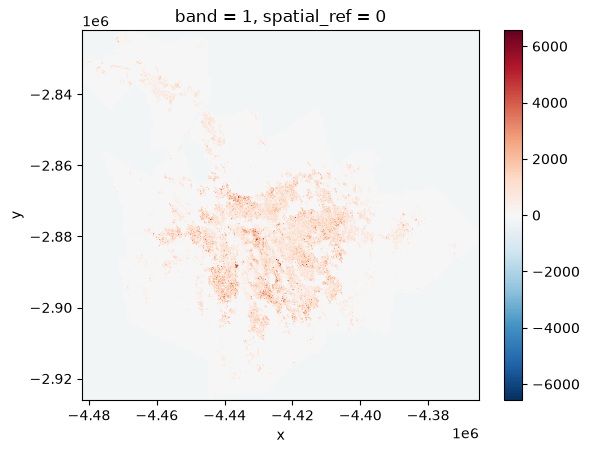

In [9]:
pop.plot()

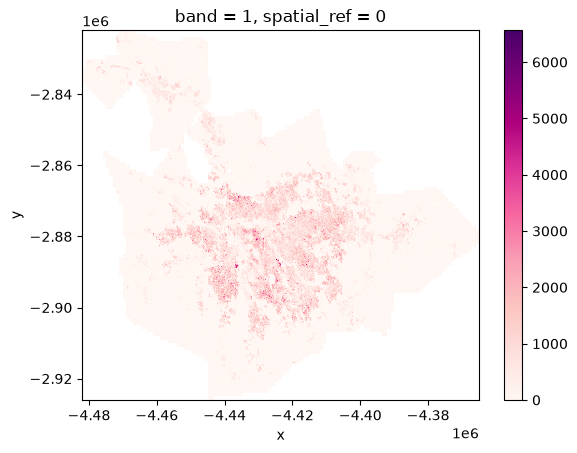

In [10]:
pop.where(pop != -200).sel(band=1).plot(cmap="RdPu");